In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
need_column = ['region', 'price', 'year', 'manufacturer', 'condition', 'cylinders', 'type', 'fuel', 'transmission', 'odometer']
df = pd.read_csv('/content/drive/MyDrive/Price on auto/vehicles.csv', usecols=need_column)
df.isna().sum()

,0
region,0
price,0
year,1205
manufacturer,17646
condition,174104
cylinders,177678
fuel,3013
odometer,4400
transmission,2556
type,92858


In [ ]:
df = df.dropna(subset=['year', 'fuel', 'transmission', 'manufacturer', 'odometer'])
df['year'] = df['year'].astype('int16')
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 401512 entries, 27 to 426879
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        401512 non-null  object 
 1   price         401512 non-null  int64  
 2   year          401512 non-null  int16  
 3   manufacturer  401512 non-null  object 
 4   condition     240034 non-null  object 
 5   cylinders     236872 non-null  object 
 6   fuel          401512 non-null  object 
 7   odometer      401512 non-null  float64
 8   transmission  401512 non-null  object 
 9   type          316308 non-null  object 
dtypes: float64(1), int16(1), int64(1), object(7)
memory usage: 31.4+ MB


In [ ]:
df['year'] = df['year'].astype('int16')
df['year'].describe().T[['mean', 'max', 'min', 'std']]
df[df['year'] == 1900]
df['condition'] = df['condition'].fillna('unknown')
df['condition'].isna().sum()

np.int64(0)

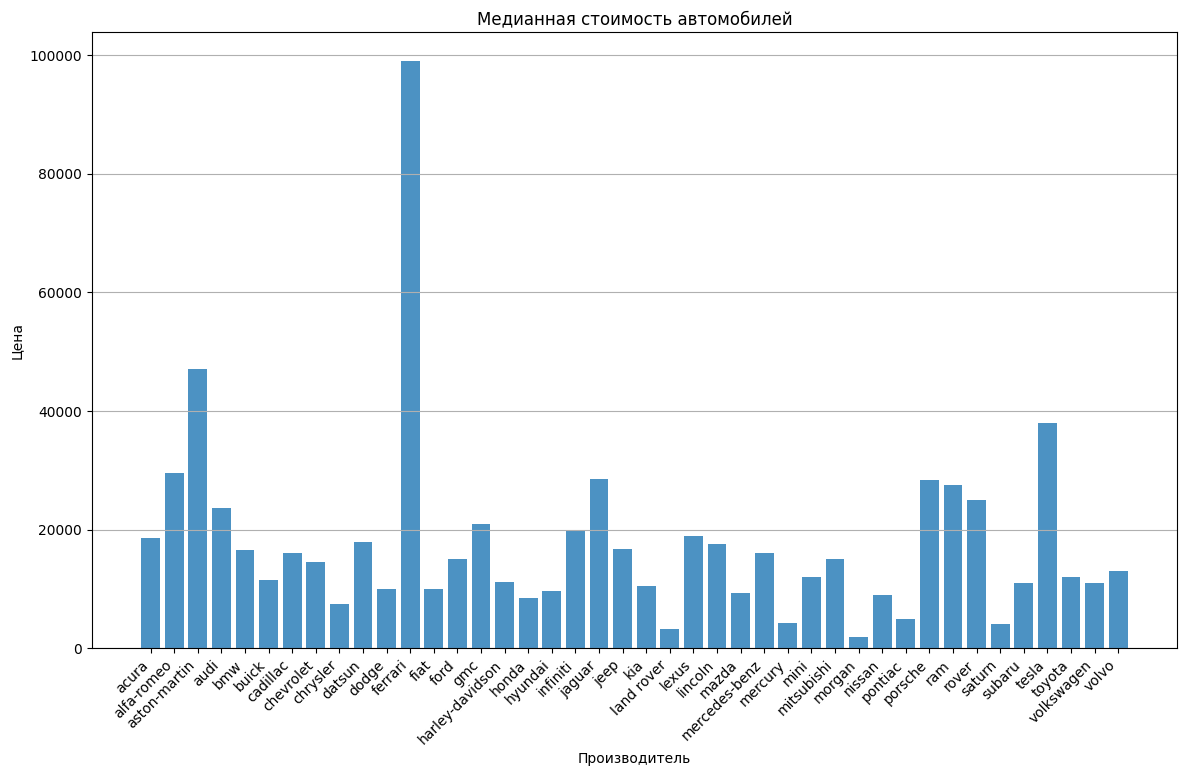

In [ ]:
clean_df = df.copy()
clean_df['manufacturer'] = clean_df['manufacturer'].fillna('unknown')
x = clean_df['manufacturer']
y = clean_df['price']
unical_x = x.unique()

median_prices = (clean_df.groupby('manufacturer')['price'].median())
median_prices


plt.figure(figsize=(14, 8))
plt.bar(median_prices.index, median_prices.values, alpha=0.8)
plt.title('Медианная стоимость автомобилей')
plt.xlabel('Производитель')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Цена')
plt.grid(axis='y', alpha=1)
plt.show()

Если цена больше 50000 - ferrari

In [ ]:
df.isna().sum()

,0
region,0
price,0
year,0
manufacturer,0
condition,0
cylinders,164640
fuel,0
odometer,0
transmission,0
type,85204


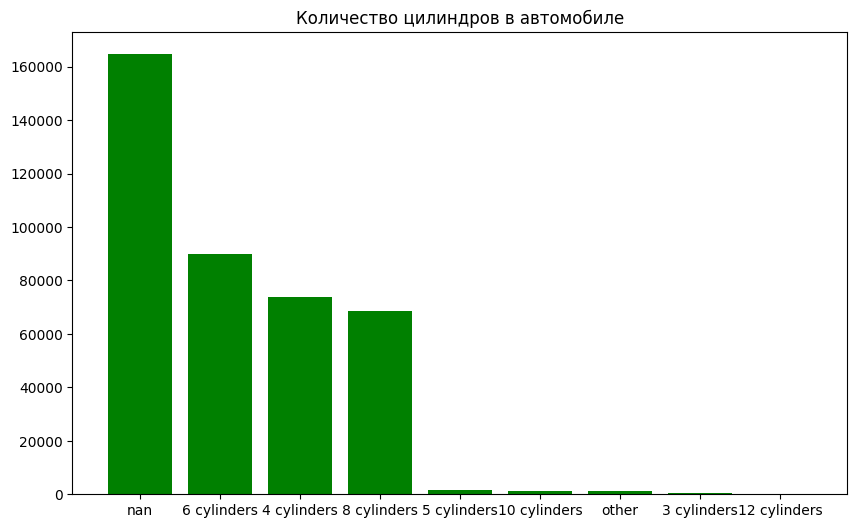

In [ ]:
unical_cyl = df['cylinders'].unique()
# df_copy2 = df.copy()
count_cyl = df['cylinders'].value_counts(dropna=False)
count_cyl.index
plt.figure(figsize=(10, 6))
plt.bar(count_cyl.index.astype(str), count_cyl.values, color='green')
plt.title('Количество цилиндров в автомобиле')
plt.show()

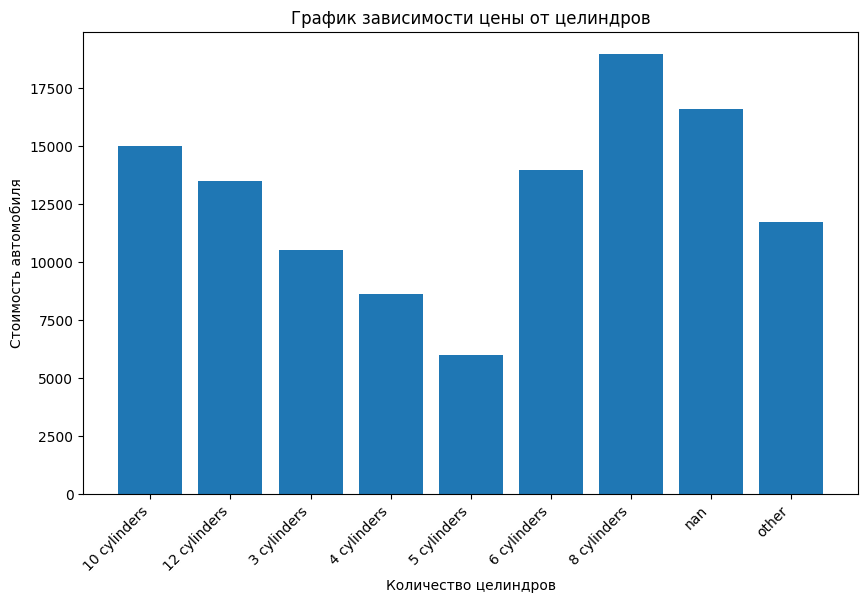

In [ ]:
copy_df = df.copy()
copy_df['cylinders'] = copy_df['cylinders'].astype(str)
group = (copy_df.groupby('cylinders')['price'].median())

plt.figure(figsize=(10, 6))
plt.bar(group.index, group.values)
plt.title('График зависимости цены от целиндров')
plt.xlabel('Количество целиндров')
plt.ylabel('Стоимость автомобиля')
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
df['cylinders'] = df['cylinders'].fillna('number')
df.isna().sum()

,0
region,0
price,0
year,0
manufacturer,0
condition,0
cylinders,0
fuel,0
odometer,0
transmission,0
type,85204


In [ ]:
type_unic = df['type'].unique()
type_car = df['type'].value_counts(dropna=False)
df['type'] = df['type'].fillna('unknown')
df.isna().sum()

,0
region,0
price,0
year,0
manufacturer,0
condition,0
cylinders,0
fuel,0
odometer,0
transmission,0
type,0


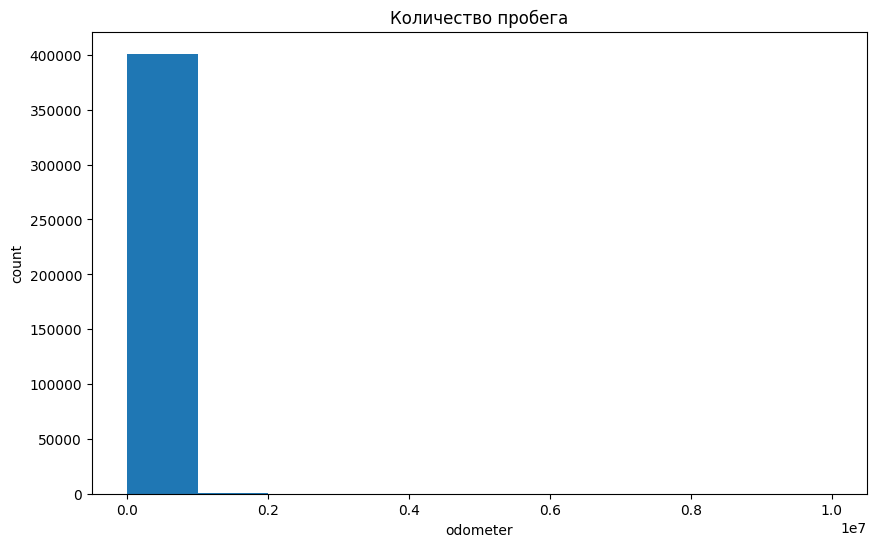

401512

In [ ]:
x = df['odometer']
y = df['price']

plt.figure(figsize=(10, 6))
plt.hist(x)
plt.title('Количество пробега')
plt.xlabel('odometer')
plt.ylabel('count')
plt.show()
len(x)

In [ ]:
from scipy.stats import trim_mean
mid_position_odometer_price = {
    'Среднее пробег': x.mean(),
    'Среднее усеченное пробег': trim_mean(x, 0.1),
    'Медиана пробег': x.median(),
    'Среднее цена': y.mean(),
    'Среднее усеченное цена': trim_mean(y, 0.05),
    'Медиана цена': y.median(),
    'Размер пробега': len(x),
    'Размер цены': len(y)
}
mid_position_odometer_price

{'Среднее пробег': np.float64(96816.39456354978),
 'Среднее усеченное пробег': np.float64(86923.18285545282),
 'Медиана пробег': 85909.0,
 'Среднее цена': np.float64(78202.6200935464),
 'Среднее усеченное цена': np.float64(16198.251797366629),
 'Медиана цена': 13994.0,
 'Размер пробега': 401512,
 'Размер цены': 401512}

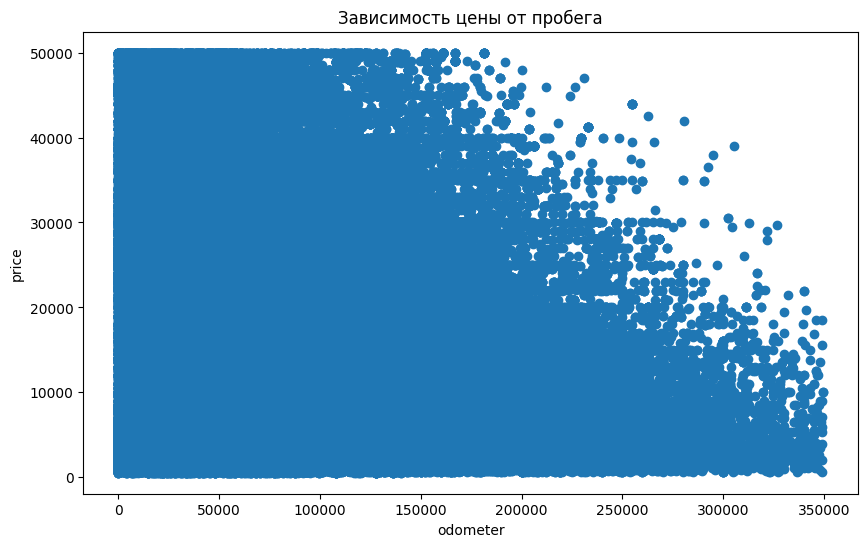

({'Среднее пробег': np.float64(94219.37144692514),
  'Среднее усеченное пробег': np.float64(90139.76204819277),
  'Медиана пробег': 90000.0,
  'Среднее цена': np.float64(17810.151581682177),
  'Среднее усеченное цена': np.float64(17232.008888635108),
  'Медиана цена': 15000.0},
 {'Size x': 350260, 'Size y': 350260, 'Min x': 0.0, 'Min y': 501})

In [ ]:
mask =(x < 350000) &  (y > 500) & (y < 50000)
x_clean = x[mask]
y_clean = y[mask]
ms_clean = {
    'Size x': len(x_clean),
    'Size y': len(y_clean),
    'Min x': x_clean.min(),
    'Min y': y_clean.min()
}
mid_position_odometer_price_clean = {
    'Среднее пробег': x_clean.mean(),
    'Среднее усеченное пробег': trim_mean(x_clean, 0.1),
    'Медиана пробег': x_clean.median(),
    'Среднее цена': y_clean.mean(),
    'Среднее усеченное цена': trim_mean(y_clean, 0.05),
    'Медиана цена': y_clean.median()
}
plt.figure(figsize=(10, 6))
plt.scatter(x_clean, y_clean)
plt.title('Зависимость цены от пробега')
plt.xlabel('odometer')
plt.ylabel('price')
plt.show()
ms_clean
mid_position_odometer_price_clean, ms_clean

In [ ]:
df = df[(df['odometer'] < 350000) & (df['price'] > 1000) & (df['price'] < 50000)]
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 346345 entries, 27 to 426879
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        346345 non-null  object 
 1   price         346345 non-null  int64  
 2   year          346345 non-null  int16  
 3   manufacturer  346345 non-null  object 
 4   condition     346345 non-null  object 
 5   cylinders     346345 non-null  object 
 6   fuel          346345 non-null  object 
 7   odometer      346345 non-null  float64
 8   transmission  346345 non-null  object 
 9   type          346345 non-null  object 
dtypes: float64(1), int16(1), int64(1), object(7)
memory usage: 27.1+ MB


In [ ]:
year = df['year']
analys_year = {
    'Медиана': year.median(),
    'Среднее': year.mean(),
    'Среднее усеченное': trim_mean(year, 0.05),
    'Size': len(year),
    'Max': year.max(),
    'Min': year.min()
}
analys_year

{'Медиана': np.float64(2013.0),
 'Среднее': np.float64(2011.144231907491),
 'Среднее усеченное': np.float64(2012.225195774291),
 'Size': 346345,
 'Max': np.int16(2022),
 'Min': np.int16(1900)}

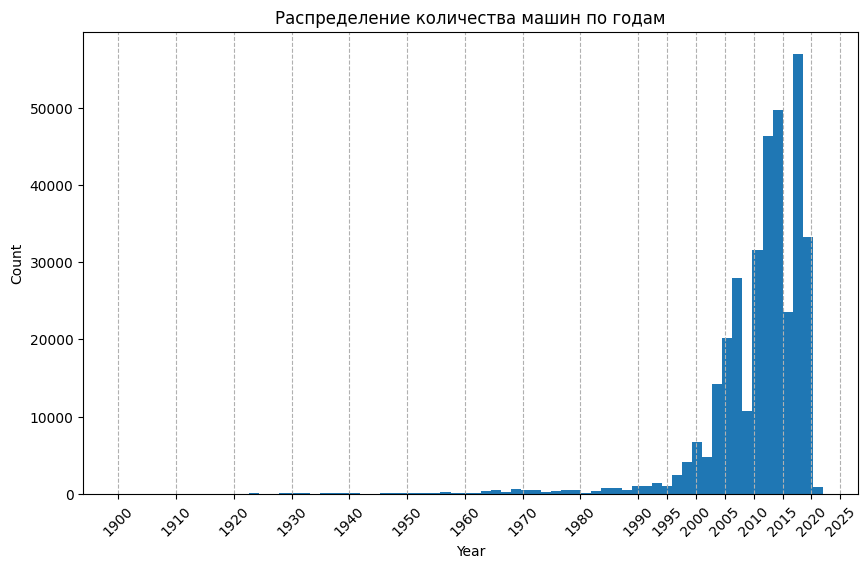

In [ ]:
plt.figure(figsize=(10, 6))
plt.hist(year, bins=70)
plt.title('Распределение количества машин по годам')
plt.xlabel('Year')
plt.ylabel('Count')
year_to_1990 = np.arange(1900, 1990, 10)
year_past_1990 = np.arange(1990, 2026, 5)
year_1900_2026 = np.concatenate((year_to_1990, year_past_1990))
plt.xticks(year_1900_2026, rotation=45)
plt.grid(True, axis='x', linestyle='--')
plt.show()

Text(0, 0.5, 'Price')

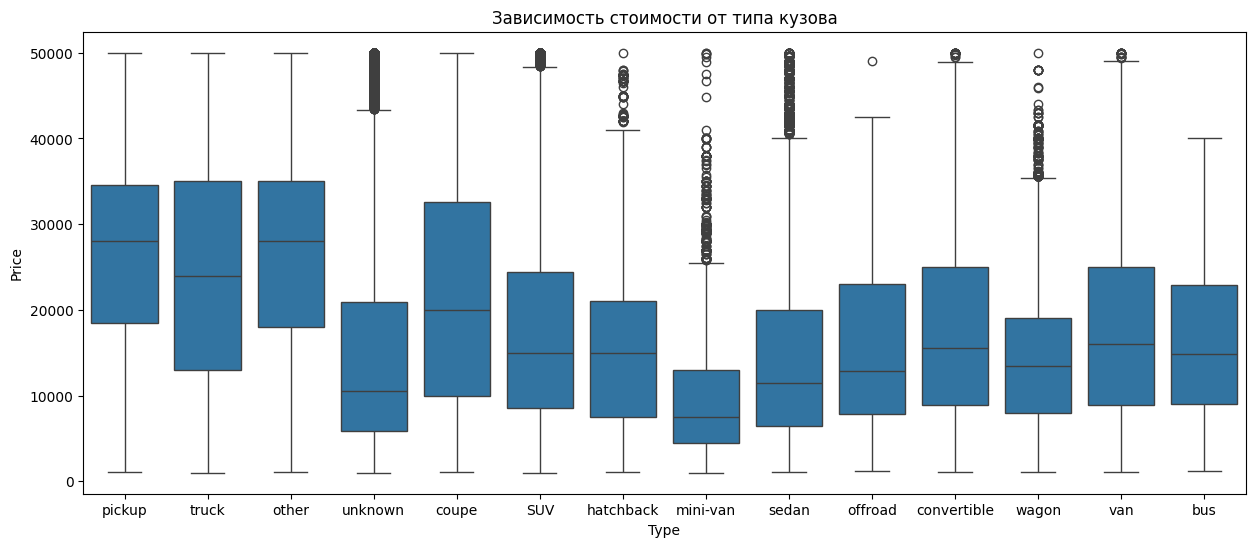

In [ ]:
import seaborn as sns
plt.figure(figsize=(15, 6))
x = df['type']
y = df['price']
# group_price_type = y.groupby(x).sort_va
sns.boxplot(x=x, y=y)
plt.title('Зависимость стоимости от типа кузова')
plt.xlabel('Type')
plt.ylabel('Price')


In [ ]:
mini_van = df[df['type'] == 'mini-van']['price']
stat_mini_van = {
    'Median': mini_van.median(),
    'Mean': mini_van.mean(),
    'Trim_mean': trim_mean(mini_van, 0.1),
    'max': mini_van.max()
}
stat_mini_van
# mini_van

{'Median': 7500.0,
 'Mean': np.float64(9843.396901072705),
 'Trim_mean': np.float64(8634.79237414358),
 'max': 49995}

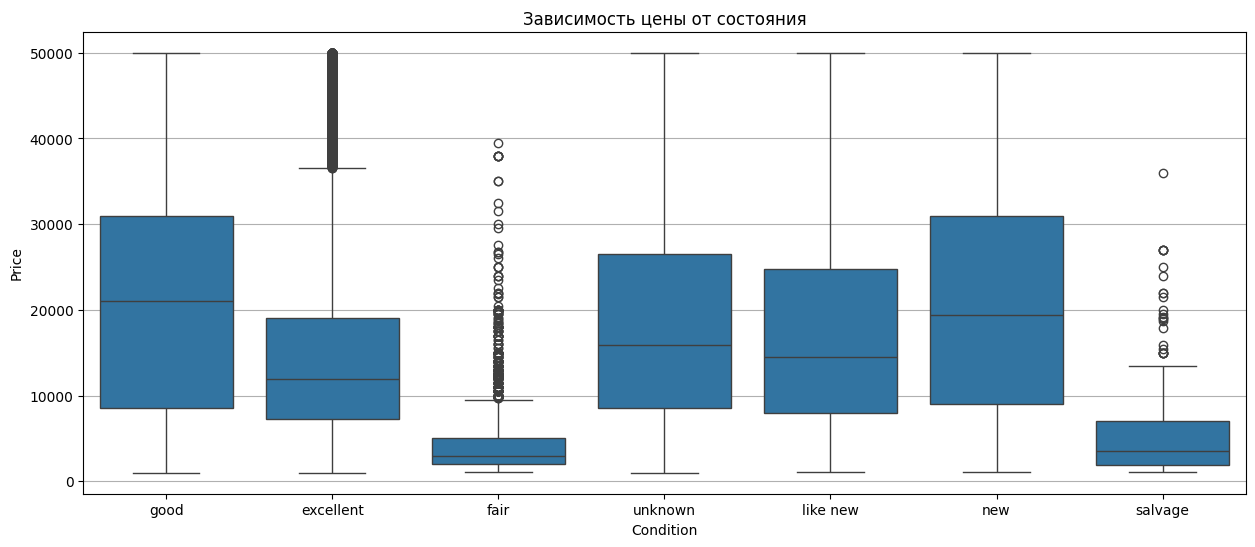

In [ ]:
x_condition = df['condition']
y_condition_price = df['price']

plt.figure(figsize=(15, 6))
sns.boxplot(x=x_condition, y=y_condition_price)
plt.title('Зависимость цены от состояния')
plt.xlabel('Condition')
plt.ylabel('Price')
plt.grid(axis='y')
plt.show()

Попробуем предсказать тип кузова и состояние машины по имеющимся данным и заполнить недостающую информацию с помощью обученной ML модели,

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
#тестовая выборка для типа
test_type = df[df['type'] == 'unknown']
test_label = test_type['type']
test_type = test_type.drop(['type'], axis=1)

#тренировочная и валидационная выборка для типа
train_type = df[df['type'] != 'unknown']
train_label = train_type['type']
train_type = train_type.drop(['type'], axis=1)

type_x_tr, type_x_val, type_y_tr, type_y_val = train_test_split(train_type, train_label, test_size=0.2, random_state=42)
type_y_tr

,type
7510,sedan
206825,other
384129,SUV
142842,SUV
65132,truck
...,...
183905,coupe
402654,SUV
202321,SUV
227235,pickup


In [ ]:
#тестовая выборка для определения состояния машины
test_condition = df[df['condition'] == 'unknown']
test_condition_target = test_condition['condition']
test_condition = test_condition.drop('condition', axis=1)

#тренировочная выборка для определения состояния
train_condition = df[df['condition'] != 'unknown']
train_condition_target = train_condition['condition']
train_condition = train_condition.drop('condition', axis=1)

#разбиение на тренировочную и валидационную выборки
x_cond_train, x_cond_valid, y_cond_train, y_cond_valid = train_test_split(train_condition, train_condition_target, test_size=0.2, random_state=42)
x_cond_train

,region,price,year,manufacturer,cylinders,fuel,odometer,transmission,type
287534,akron / canton,40990,2019,chevrolet,8 cylinders,gas,16539.0,other,coupe
9858,phoenix,11888,2016,ford,4 cylinders,gas,89555.0,automatic,SUV
39207,modesto,35995,2017,toyota,6 cylinders,gas,28420.0,automatic,pickup
98143,jacksonville,11900,2012,volkswagen,4 cylinders,gas,69292.0,automatic,SUV
398707,roanoke,33590,2020,cadillac,number,other,15050.0,other,sedan
...,...,...,...,...,...,...,...,...,...
230877,asheville,27590,2016,acura,6 cylinders,gas,40762.0,automatic,SUV
197593,detroit metro,1995,2019,ram,6 cylinders,gas,19000.0,automatic,pickup
254835,north jersey,35000,2017,toyota,6 cylinders,gas,55164.0,automatic,SUV
279699,rochester,5100,2001,ford,6 cylinders,gas,106000.0,manual,convertible
